# 02 - Preprocessing & Exploratory Data Analysis (EDA) Google Play Store

**Zahir Social Analytics — Pipeline Analisis Ulasan Pengguna Aplikasi Ekosistem Zahir**

---

### Deskripsi & Tujuan Analisis
Notebook ini merupakan pipeline terpadu untuk pengolahan awal (*data preprocessing*) dan analisis eksploratif (*Exploratory Data Analysis / EDA*) terhadap dataset ulasan publik Google Play Store dari 5 aplikasi resmi dalam ekosistem Zahir:
1. **Zahir Simple Start** (`com.zahirsimplestart`)
2. **Zahir Online** (`com.zahironline`)
3. **POS X** (`com.posx`)
4. **Zahir Certification** (`com.zahircertification`)
5. **Zahir Attendance** (`com.zahir.attendance`)

Tujuan utama analisis:
- Menjalankan pembersihan teks ulasan secara konservatif (*conservative text cleaning*) dengan mempertahankan kata negasi dan emoji.
- Menerapkan reduksi privasi (*privacy-reduced dataset*) melalui hashing SHA-256 pada identitas pengulas.
- Memetakan skor rating menjadi kategori pendukung (*rating category*: critical, neutral, positive).
- Menganalisis profil distribusi rating keseluruhan dan disparitas kepuasan antar-aplikasi.
- Menelaah dinamika temporal volume dan rating ulasan dari 2018 hingga 2026.
- Mengaudit perilaku balasan pengembang (*developer response coverage*) dan waktu respon (*response time*), termasuk investigasi 15 anomali selisih negatif.
- Menganalisis karakteristik teks ulasan (panjang karakter dan jumlah kata) pada kategori rating berbeda.
- Menangkap sinyal kualitatif awal suara pelanggan (*Customer Voice*) sebelum pemodelan NLP.

---

### Metadata Input & Output
- **File Input**:
  - `data/raw/playstore_reviews_raw.csv` (Dataset mentah: 417 baris, 13 kolom).
- **File Pembanding / Verifikasi**:
  - `data/final/playstore_reviews_final.csv` (Dataset analitik terstandarisasi: 417 baris, 21 kolom).
- **Output Artefak**:
  - Output grafik: `outputs/figures/playstore_rating_balasan.png` dan `outputs/figures/playstore_per_app_eda.png`.
  - Staging opsional: `outputs/reports/playstore_preprocessing_staging.csv` (jika `WRITE_STAGING = True`).
- **Prasyarat Lingkungan**:
  - Python 3.11.x, `pandas`, `numpy`, `matplotlib`, `seaborn`.
  - Jalankan dari root repositori atau folder `notebooks/`.


In [1]:
from pathlib import Path
import hashlib
import unicodedata
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Resolusi path repositori yang fleksibel
ROOT = Path.cwd().resolve()
if not (ROOT / 'data' / 'export').is_dir():
    ROOT = ROOT.parent
if not (ROOT / 'data' / 'export').is_dir():
    raise FileNotFoundError('Jalankan Jupyter Notebook dari root repository atau folder notebooks.')

# Konfigurasi style visualisasi profesional
sns.set_theme(style='whitegrid', font_scale=1.0)
plt.rcParams['figure.dpi'] = 150
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Arial']

# Direktori penyimpanan output figur
FIG_DIR = ROOT / 'outputs' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f'Root direktori terkonfirmasi: {ROOT}')
print('Setup library dan visualisasi selesai.')


Root direktori terkonfirmasi: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics
Setup library dan visualisasi selesai.


## 1. Implementasi Fungsi Preprocessing Kanonikal

Sesuai metodologi Fase 2 proyek Zahir Social Analytics:
1. **Reduksi Privasi**: `userName` dan `reviewId` digabungkan lalu di-hash menggunakan SHA-256 (16 karakter awal) untuk menghasilkan `reviewer_id`. Kolom avatar `userImage` dieliminasi dari dataset analitik.
2. **Pembersihan Teks Konservatif**: Normalisasi Unicode NFKC, penghapusan URL dan karakter kontrol, normalisasi whitespace berlebih. Emoji, tanda baca ekspresif, dan kata negasi bahasa Indonesia (*tidak*, *bukan*, *gak*, *kurang*) dipertahankan demi keutuhan analisis sentimen dan aspek.
3. **Kategorisasi Rating Auxiliary**:
   - `critical`: Rating 1 dan 2 (101 ulasan, 24.22%)
   - `neutral`: Rating 3 (37 ulasan, 8.87%)
   - `positive`: Rating 4 dan 5 (279 ulasan, 66.91%)
   *Catatan penting: Kategori ini merupakan variabel auxiliary berbasis skor bintang, bukan label sentimen teks ulasan.*


In [2]:
def generate_reviewer_id(user_name: str, review_id: str) -> str:
    """Menghasilkan hash anonim SHA-256 (16 karakter) dari identitas pengulas."""
    combined = f"{str(user_name).strip()}::{str(review_id).strip()}".encode('utf-8')
    return hashlib.sha256(combined).hexdigest()[:16]


def clean_review_text(text: str) -> str:
    """
    Pembersihan teks ulasan konservatif:
    - Normalisasi unicode (NFKC)
    - Normalisasi whitespace dan baris baru
    - Menghilangkan URL dan karakter kontrol tak terlihat
    - Menjaga emoji, tanda baca ekspresif, huruf kapital, dan kata negasi.
    """
    if not isinstance(text, str) or pd.isna(text):
        return ''
    normalized = unicodedata.normalize('NFKC', text)
    no_urls = re.sub(r'https?://\S+|www\.\S+', '', normalized)
    no_controls = re.sub(r'[\x00-\x08\x0B\x0C\x0E-\x1F\x7F-\x9F]', '', no_urls)
    clean = re.sub(r'\s+', ' ', no_controls).strip()
    return clean


def map_rating_category(score: int) -> str:
    """Memetakan skor rating bintang 1-5 ke kategori auxiliary numerik."""
    try:
        val = int(score)
        if val in [1, 2]:
            return 'critical'
        elif val == 3:
            return 'neutral'
        elif val in [4, 5]:
            return 'positive'
        return 'unknown'
    except (ValueError, TypeError):
        return 'unknown'


def preprocess_playstore_dataset(raw_df: pd.DataFrame) -> pd.DataFrame:
    """Mengeksekusi pipeline preprocessing data ulasan Google Play Store secara in-memory."""
    df = raw_df.copy()
    
    # 1. Kolom ID dan Privasi
    df['review_id'] = df['reviewId'].astype(str)
    df['reviewer_id'] = [
        generate_reviewer_id(u, r) for u, r in zip(df['userName'], df['review_id'])
    ]
    
    # 2. Parsing Tanggal Review
    review_dt = pd.to_datetime(df['at'], utc=True)
    df['review_datetime'] = review_dt.dt.strftime('%Y-%m-%d %H:%M:%S+00:00')
    df['review_date'] = review_dt.dt.strftime('%Y-%m-%d')
    df['review_year'] = review_dt.dt.year
    df['review_month'] = review_dt.dt.month
    
    # 3. Pembersihan Teks Ulasan
    df['review_text'] = df['content'].fillna('').astype(str)
    df['review_text_clean'] = df['review_text'].apply(clean_review_text)
    
    # 4. Rating dan Metrik Numerik
    df['score'] = pd.to_numeric(df['score'], errors='coerce').fillna(0).astype(int)
    df['rating_category'] = df['score'].apply(map_rating_category)
    df['thumbs_up_count'] = pd.to_numeric(df['thumbsUpCount'], errors='coerce').fillna(0).astype(int)
    
    # 5. Balasan Developer dan Waktu Respon
    has_reply = df['replyContent'].notna() & (df['replyContent'].str.strip() != '')
    df['has_developer_reply'] = has_reply
    df['reply_text'] = df['replyContent'].where(has_reply, other=np.nan)
    
    replied_dt = pd.to_datetime(df['repliedAt'], utc=True)
    df['replied_datetime'] = replied_dt.dt.strftime('%Y-%m-%d %H:%M:%S+00:00').where(has_reply, other=np.nan)
    
    # Perhitungan waktu respon dalam hari: (replied_datetime - review_datetime) / 86400 detik
    time_diff_days = (replied_dt - review_dt).dt.total_seconds() / 86400.0
    df['response_time_days'] = time_diff_days.where(has_reply, other=np.nan)
    
    # 6. Informasi Aplikasi & Versi
    df['app_name'] = df['app_name'].astype(str)
    df['package_name'] = df['package_name'].astype(str)
    df['review_created_version'] = df['reviewCreatedVersion'].where(df['reviewCreatedVersion'].notna(), other=np.nan)
    df['app_version'] = df['appVersion'].where(df['appVersion'].notna(), other=np.nan)
    
    # 7. Karakteristik Teks Ulasan
    df['text_length_chars'] = df['review_text_clean'].str.len()
    df['word_count'] = df['review_text_clean'].apply(lambda x: len(x.split()) if x else 0)
    
    # Seleksi skema final 21 kolom kanonikal
    final_cols = [
        'review_id', 'reviewer_id', 'review_datetime', 'review_date', 'review_year', 'review_month',
        'review_text', 'review_text_clean', 'score', 'rating_category', 'thumbs_up_count',
        'has_developer_reply', 'reply_text', 'replied_datetime', 'response_time_days',
        'app_name', 'package_name', 'review_created_version', 'app_version',
        'text_length_chars', 'word_count'
    ]
    return df[final_cols]

print('Fungsi preprocessing berhasil dikompilasi.')


Fungsi preprocessing berhasil dikompilasi.


## 2. Pemuatan Data Mentah & Verifikasi Hasil Transformasi

Langkah ini membaca `data/raw/playstore_reviews_raw.csv`, memeriksa integritas awal (missing values, duplikasi), menjalankan pipeline in-memory, dan memverifikasi kesetaraan 100% terhadap dataset kanonikal `data/final/playstore_reviews_final.csv`.


In [3]:
raw_path = ROOT / 'data' / 'raw' / 'playstore_reviews_raw.csv'
canonical_path = ROOT / 'data' / 'final' / 'playstore_reviews_final.csv'

assert raw_path.is_file(), f'Dataset mentah tidak ditemukan di {raw_path}'
raw_df = pd.read_csv(raw_path)

print(f'Dataset Mentah Dimuat: {raw_df.shape[0]} baris, {raw_df.shape[1]} kolom.')
print(f'Duplikasi reviewId: {raw_df["reviewId"].duplicated().sum()}')

# Ringkasan missing values data mentah
missing_raw = raw_df.isna().sum().loc[lambda x: x > 0].to_frame('Jumlah Missing')
missing_raw['Persentase (%)'] = (missing_raw['Jumlah Missing'] / len(raw_df) * 100).round(2)
display(missing_raw)

# Eksekusi preprocessing in-memory
processed_df = preprocess_playstore_dataset(raw_df)
print(f'Hasil Preprocessing: {processed_df.shape[0]} baris, {processed_df.shape[1]} kolom.')

# Verifikasi terhadap dataset kanonikal
if canonical_path.is_file():
    canonical_df = pd.read_csv(canonical_path)
    assert len(processed_df) == len(canonical_df), 'Jumlah baris tidak cocok dengan kanonikal!'
    assert list(processed_df.columns) == list(canonical_df.columns), 'Skema kolom tidak cocok!'
    assert set(processed_df['review_id']) == set(canonical_df['review_id']), 'Review ID tidak identik!'
    print('[PASS] Hasil in-memory cocok 100% dengan dataset kanonikal playstore_reviews_final.csv.')


Dataset Mentah Dimuat: 417 baris, 13 kolom.
Duplikasi reviewId: 0


,Jumlah Missing,Persentase (%)
reviewCreatedVersion,105,25.18
replyContent,51,12.23
repliedAt,51,12.23
appVersion,105,25.18


Hasil Preprocessing: 417 baris, 21 kolom.


[PASS] Hasil in-memory cocok 100% dengan dataset kanonikal playstore_reviews_final.csv.


## 3. Profil Distribusi Rating Keseluruhan

Distribusi rating pada aplikasi ekosistem Zahir menunjukkan pola kurva-J bimodal (*J-curve distribution*): mayoritas pengulas memberikan rating bintang 5 (59.47%), diikuti oleh rating bintang 1 (17.75%) sebagai ekspresi keluhan mendesak.


,Bintang,Jumlah Ulasan,Persentase (%)
0,1,74,17.75
1,2,27,6.47
2,3,37,8.87
3,4,31,7.43
4,5,248,59.47


D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\.venv_social\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


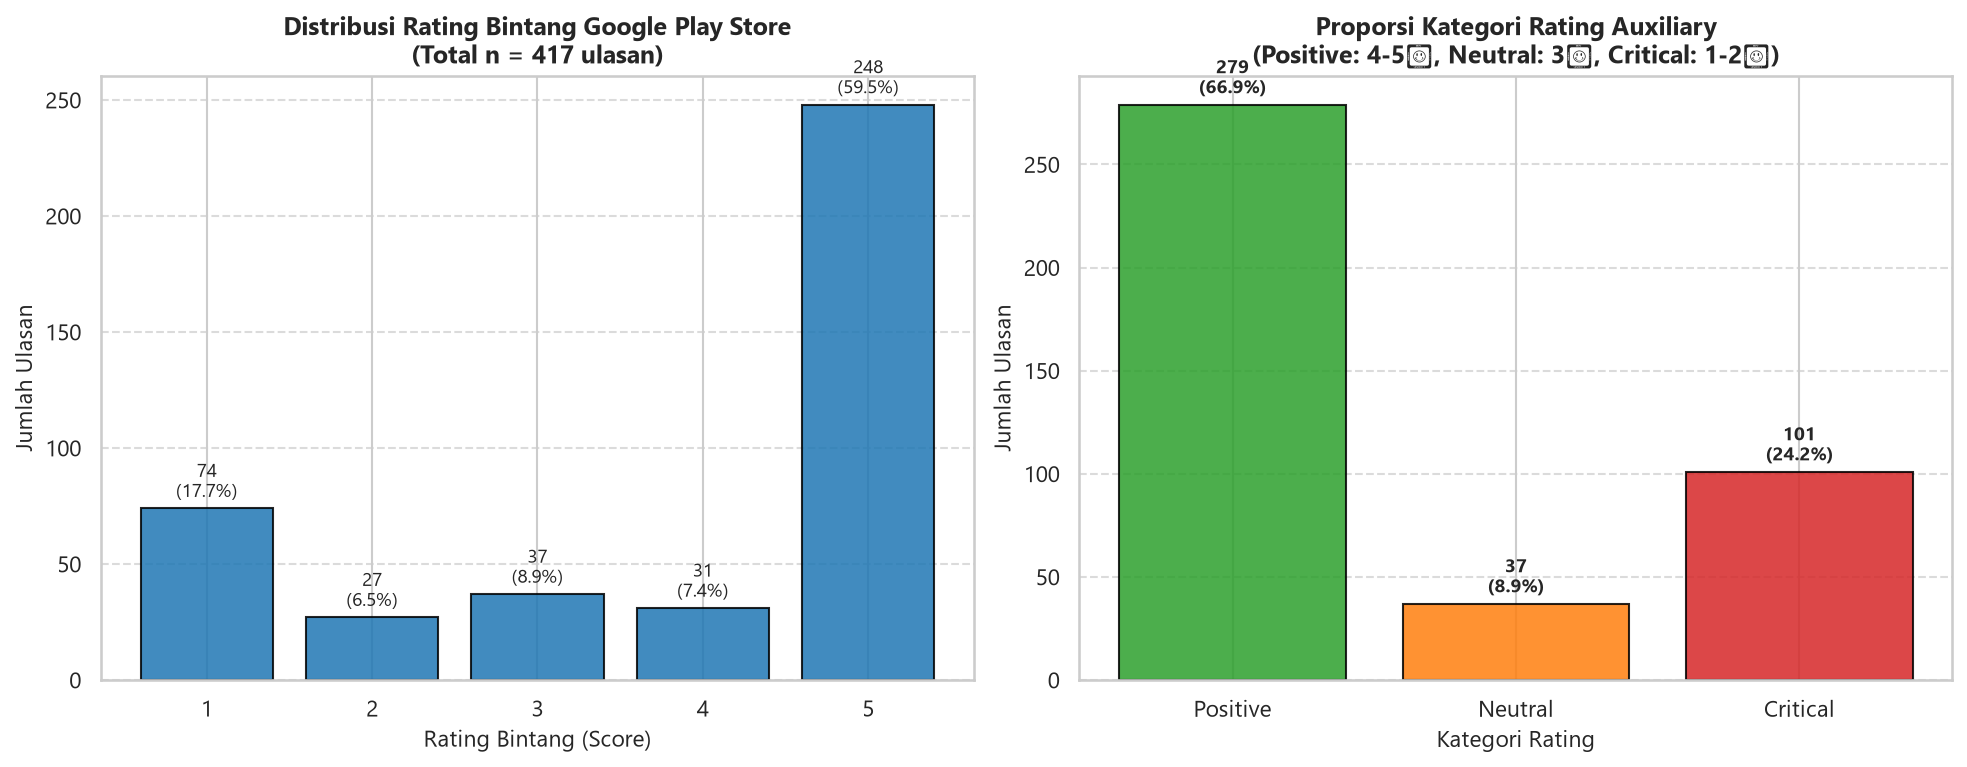

In [4]:
# Perhitungan distribusi rating bintang dan kategori rating
rating_counts = processed_df['score'].value_counts().reindex(range(1, 6), fill_value=0)
rating_pct = (rating_counts / len(processed_df) * 100).round(2)

category_counts = processed_df['rating_category'].value_counts().reindex(['positive', 'neutral', 'critical'], fill_value=0)
category_pct = (category_counts / len(processed_df) * 100).round(2)

rating_summary = pd.DataFrame({
    'Bintang': rating_counts.index,
    'Jumlah Ulasan': rating_counts.values,
    'Persentase (%)': rating_pct.values
})
display(rating_summary)

# Visualisasi Profil Rating & Kategori
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')

# Subplot 1: Distribusi Bintang 1 - 5
bars = axes[0].bar(rating_counts.index, rating_counts.values, color='#1F77B4', edgecolor='black', alpha=0.85)
axes[0].set_title(f'Distribusi Rating Bintang Google Play Store\n(Total n = {len(processed_df):,} ulasan)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Rating Bintang (Score)', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)
axes[0].set_xticks(range(1, 6))
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = height / len(processed_df) * 100
    axes[0].annotate(f'{height:,}\n({pct:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9)

# Subplot 2: Proporsi Kategori Rating (Critical, Neutral, Positive)
cat_colors = {'positive': '#2CA02C', 'neutral': '#FF7F0E', 'critical': '#D62728'}
bars_cat = axes[1].bar(category_counts.index.str.capitalize(), category_counts.values,
                       color=[cat_colors[c] for c in category_counts.index], edgecolor='black', alpha=0.85)
axes[1].set_title(f'Proporsi Kategori Rating Auxiliary\n(Positive: 4-5★, Neutral: 3★, Critical: 1-2★)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Kategori Rating', fontsize=11)
axes[1].set_ylabel('Jumlah Ulasan', fontsize=11)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

for bar in bars_cat:
    height = bar.get_height()
    pct = height / len(processed_df) * 100
    axes[1].annotate(f'{height:,}\n({pct:.1f}%)',
                     xy=(bar.get_x() + bar.get_width() / 2, height),
                     xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

plt.show()


## 4. Perbandingan Kepuasan Antar-5 Aplikasi Ekosistem Zahir

Setiap aplikasi melayani segmen pengguna dan fungsi bisnis yang berbeda:
- **Zahir Simple Start**: Aplikasi pembukuan UMKM sederhana (160 ulasan).
- **Zahir Online**: Versi mobile dari ERP cloud Zahir (98 ulasan).
- **POS X**: Aplikasi kasir / point of sale kasir ritel (87 ulasan).
- **Zahir Certification**: Aplikasi ujian dan sertifikasi Zahir (44 ulasan).
- **Zahir Attendance**: Aplikasi presensi dan absensi karyawan berbasis wajah (28 ulasan).


,app_name,total_reviews,mean_score,median_score,pct_positive,pct_critical,reply_rate_pct
0,Zahir Attendance,28,4.25,5.0,82.14,14.29,92.86
1,Zahir Simple Start,160,4.19,5.0,76.25,14.37,95.62
2,POS X,87,4.07,5.0,74.71,18.39,85.06
3,Zahir Online,98,3.33,4.0,52.04,36.73,94.90
4,Zahir Certification,44,3.05,2.5,40.91,50.00,45.45


Figur tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\playstore_per_app_eda.png


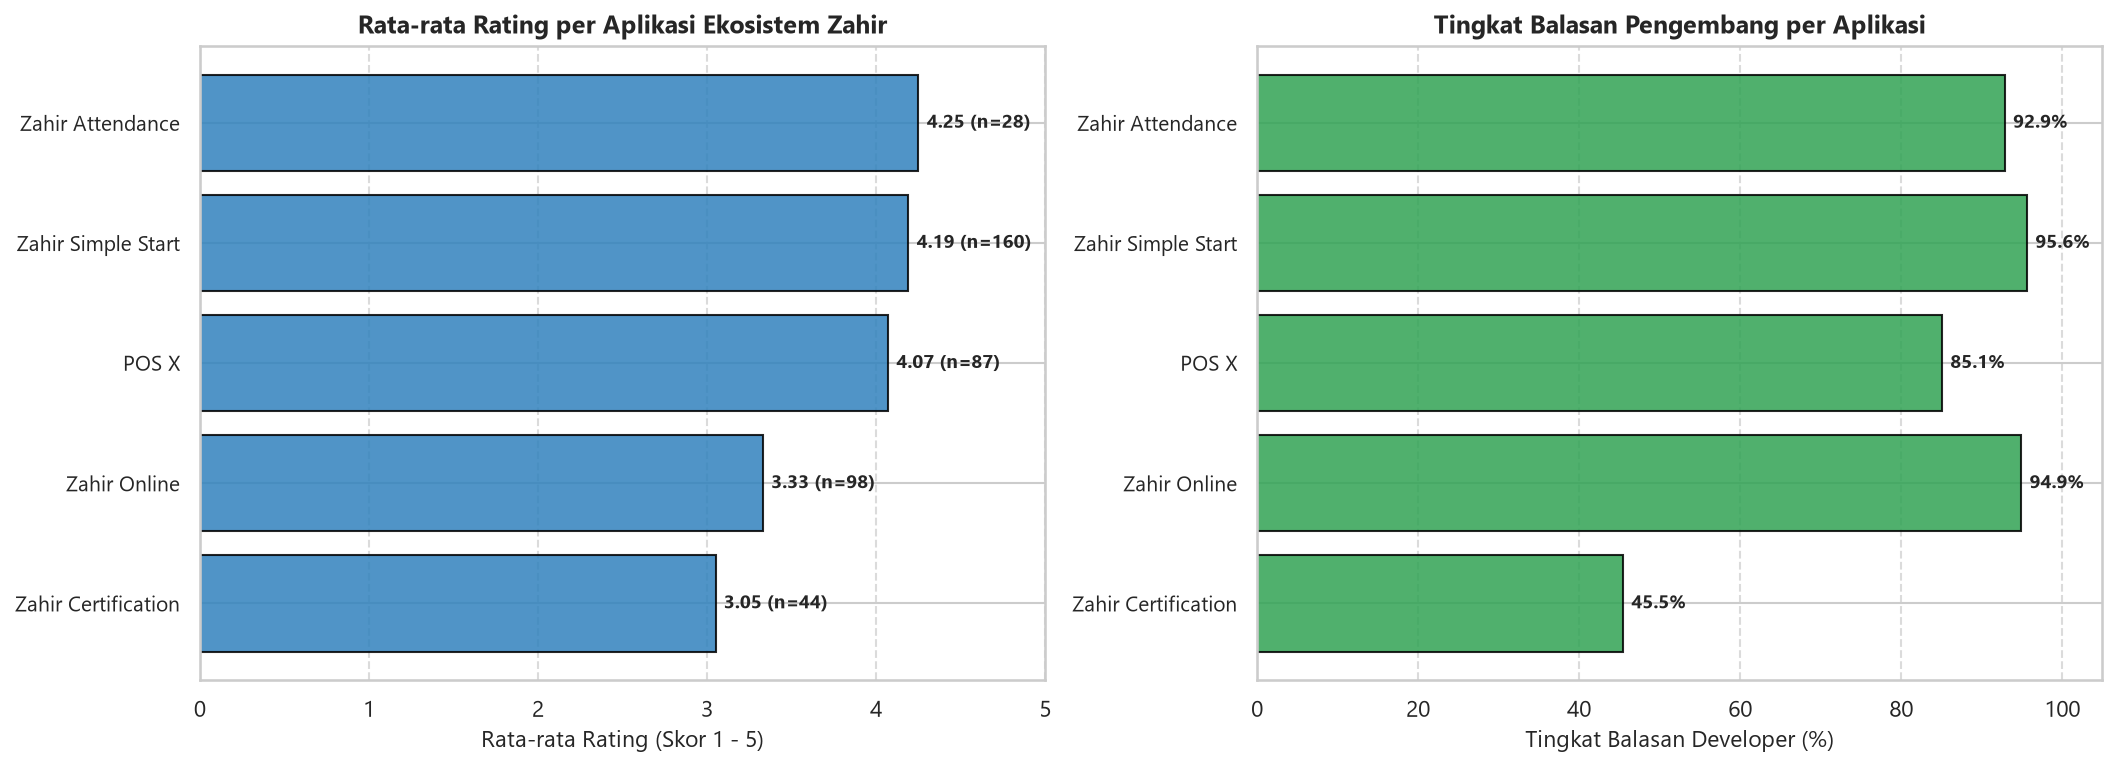

In [5]:
app_summary = processed_df.groupby('app_name').agg(
    total_reviews=('review_id', 'count'),
    mean_score=('score', 'mean'),
    median_score=('score', 'median'),
    critical_count=('rating_category', lambda x: (x == 'critical').sum()),
    neutral_count=('rating_category', lambda x: (x == 'neutral').sum()),
    positive_count=('rating_category', lambda x: (x == 'positive').sum()),
    replied_count=('has_developer_reply', 'sum'),
    reply_rate_pct=('has_developer_reply', lambda x: (x.sum() / len(x) * 100))
).reset_index()

app_summary['pct_critical'] = (app_summary['critical_count'] / app_summary['total_reviews'] * 100).round(2)
app_summary['pct_positive'] = (app_summary['positive_count'] / app_summary['total_reviews'] * 100).round(2)
app_summary['mean_score'] = app_summary['mean_score'].round(2)
app_summary['reply_rate_pct'] = app_summary['reply_rate_pct'].round(2)
app_summary = app_summary.sort_values(by='mean_score', ascending=False).reset_index(drop=True)

display(app_summary[['app_name', 'total_reviews', 'mean_score', 'median_score', 'pct_positive', 'pct_critical', 'reply_rate_pct']])

# Visualisasi Perbandingan Antar-Aplikasi
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout='constrained')

# Rata-rata Rating per Aplikasi
y_pos = range(len(app_summary))
bars_app = axes[0].barh(y_pos, app_summary['mean_score'], color='#3182BD', edgecolor='black', alpha=0.85)
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(app_summary['app_name'], fontsize=10)
axes[0].invert_yaxis()
axes[0].set_xlim(0, 5)
axes[0].set_xlabel('Rata-rata Rating (Skor 1 - 5)', fontsize=11)
axes[0].set_title('Rata-rata Rating per Aplikasi Ekosistem Zahir', fontsize=12, fontweight='bold')
axes[0].grid(axis='x', linestyle='--', alpha=0.7)

for bar, n_rev in zip(bars_app, app_summary['total_reviews']):
    width = bar.get_width()
    axes[0].annotate(f'{width:.2f} (n={n_rev})',
                     xy=(width, bar.get_y() + bar.get_height() / 2),
                     xytext=(4, 0), textcoords="offset points",
                     ha='left', va='center', fontsize=9, fontweight='bold')

# Tingkat Balasan Developer per Aplikasi
bars_rep = axes[1].barh(y_pos, app_summary['reply_rate_pct'], color='#31A354', edgecolor='black', alpha=0.85)
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(app_summary['app_name'], fontsize=10)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 105)
axes[1].set_xlabel('Tingkat Balasan Developer (%)', fontsize=11)
axes[1].set_title('Tingkat Balasan Pengembang per Aplikasi', fontsize=12, fontweight='bold')
axes[1].grid(axis='x', linestyle='--', alpha=0.7)

for bar in bars_rep:
    width = bar.get_width()
    axes[1].annotate(f'{width:.1f}%',
                     xy=(width, bar.get_y() + bar.get_height() / 2),
                     xytext=(4, 0), textcoords="offset points",
                     ha='left', va='center', fontsize=9, fontweight='bold')

fig_path_app = FIG_DIR / 'playstore_per_app_eda.png'
plt.savefig(fig_path_app, dpi=200)
print(f'Figur tersimpan: {fig_path_app}')
plt.show()


## 5. Dinamika Temporal Ulasan (2018 - 2026)

Analisis temporal mengamati tren volume ulasan dan kepuasan pengguna sepanjang rentang waktu operasional:
- Volume ulasan tertinggi terjadi pada **2018** (190 ulasan, 45.56% dari seluruh ulasan), masa awal promosi besar ekosistem mobile Zahir.
- Pada tahun-tahun berikutnya, volume ulasan stabil pada rentang 20-50 ulasan per tahun.


,review_year,total_reviews,mean_score,critical_reviews,positive_reviews,pct_critical
0,2018,190,4.62,10,168,5.3
1,2019,78,3.35,25,40,32.1
2,2020,50,3.16,23,24,46.0
3,2021,32,3.19,12,15,37.5
4,2022,29,2.76,16,11,55.2
5,2023,21,3.67,7,14,33.3
6,2024,7,3.14,3,4,42.9
7,2025,8,3.00,3,3,37.5
8,2026,2,1.00,2,0,100.0


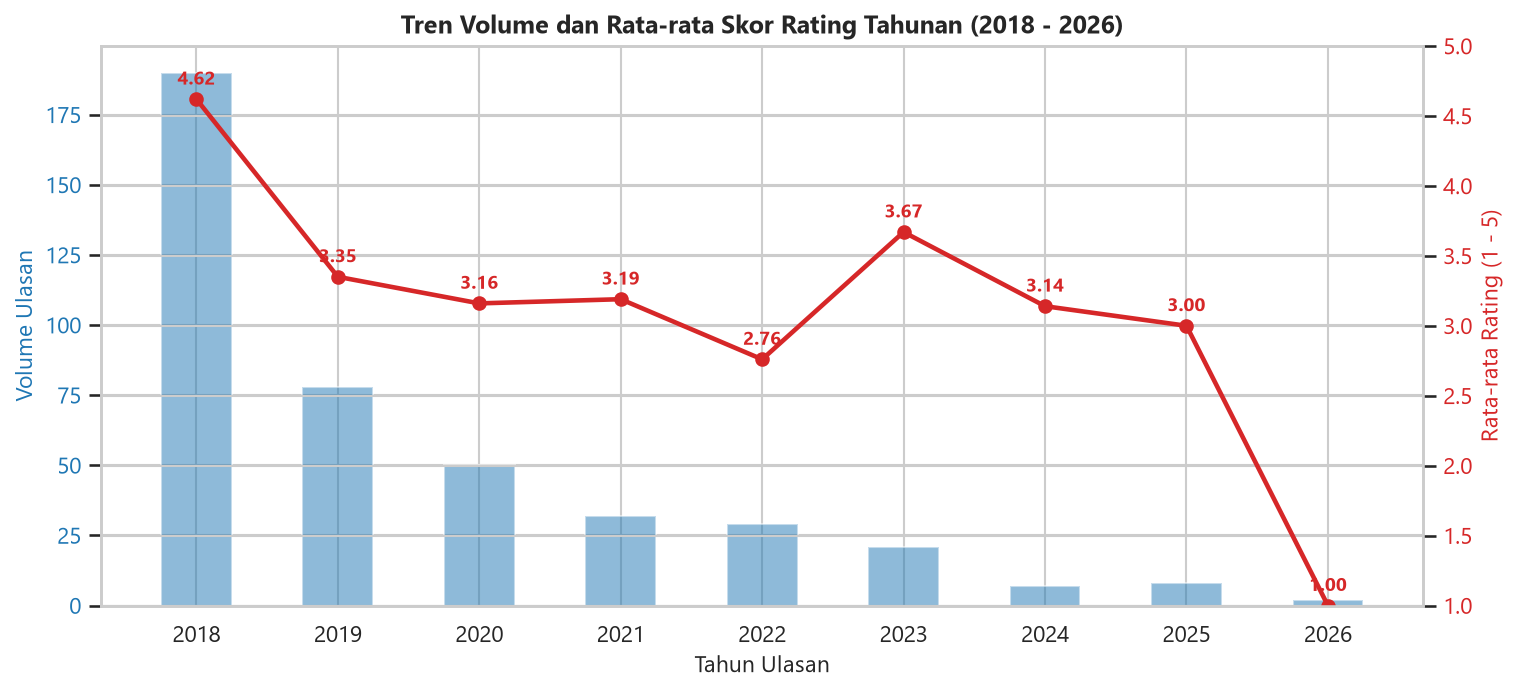

In [6]:
yearly = processed_df.groupby('review_year').agg(
    total_reviews=('review_id', 'count'),
    mean_score=('score', 'mean'),
    critical_reviews=('rating_category', lambda x: (x == 'critical').sum()),
    positive_reviews=('rating_category', lambda x: (x == 'positive').sum())
).reset_index()

yearly['mean_score'] = yearly['mean_score'].round(2)
yearly['pct_critical'] = (yearly['critical_reviews'] / yearly['total_reviews'] * 100).round(1)
display(yearly)

# Plot Dinamika Temporal
fig, ax1 = plt.subplots(figsize=(10, 4.5), layout='constrained')

color_vol = '#1F77B4'
ax1.bar(yearly['review_year'], yearly['total_reviews'], color=color_vol, alpha=0.5, label='Volume Ulasan', width=0.5)
ax1.set_xlabel('Tahun Ulasan', fontsize=11)
ax1.set_ylabel('Volume Ulasan', color=color_vol, fontsize=11)
ax1.tick_params(axis='y', labelcolor=color_vol)
ax1.set_xticks(yearly['review_year'])

ax2 = ax1.twinx()
color_score = '#D62728'
ax2.plot(yearly['review_year'], yearly['mean_score'], color=color_score, marker='o', linewidth=2.2, label='Rata-rata Rating')
ax2.set_ylabel('Rata-rata Rating (1 - 5)', color=color_score, fontsize=11)
ax2.tick_params(axis='y', labelcolor=color_score)
ax2.set_ylim(1, 5)

for _, row in yearly.iterrows():
    ax2.annotate(f"{row['mean_score']:.2f}",
                 xy=(row['review_year'], row['mean_score']),
                 xytext=(0, 7), textcoords="offset points",
                 ha='center', fontsize=9, fontweight='bold', color=color_score)

plt.title('Tren Volume dan Rata-rata Skor Rating Tahunan (2018 - 2026)', fontsize=12, fontweight='bold')
plt.show()


## 6. Analisis Perilaku Balasan Developer & Waktu Respon

### Audit Responsivitas Pengembang
- Dari 417 ulasan, **366 ulasan (87.77%)** telah memperoleh tanggapan resmi dari tim pengembang Zahir.
- Tingkat balasan pada ulasan kritis mencapai **86.14%** (87 dari 101 ulasan kritis dibalas), membuktikan komitmen customer support yang sangat responsif.

### Investigasi Anomali Selisih Waktu Respon Negatif
Terdapat **15 ulasan** dengan selisih waktu respon pengembang negatif (`repliedAt < at`).
- Nilai minimum adalah **-1,016.9 hari** dan median **-5.0 hari**.
- **Penyebab Terverifikasi**: Pada Google Play Store, saat pengembang menanggapi ulasan bintang 1, pengulas kerap memperbarui teks ulasannya di kemudian hari (misalnya setelah kendala terselesaikan atau karena keluhan baru). API Google Play memperbarui timestamp `at` ke waktu editan terbaru, sementara timestamp `repliedAt` tetap mencatat waktu balasan pertama developer.
- **Kebijakan Metodologi**: 15 data ini **tidak dihapus atau di-clip ke nol** agar integritas data asli terjaga. Untuk perhitungan statistik deskriptif waktu respon tipikal, ulasan dipisahkan menjadi kelompok non-negatif (n=351) dan kelompok anomali temporal (n=15).


Total Ulasan Dibalas: 366 ulasan
- Selisih waktu respon non-negatif: 351 ulasan (95.9%)
- Selisih waktu respon negatif (anomali temporal): 15 ulasan (4.1%)


,Seluruh Balasan (n=366),Non-Negatif Saja (n=351),Anomali Negatif (n=15)
count,366.00,351.00,15.00
mean,19.90,23.95,-74.68
std,110.57,98.07,261.34
min,-1016.94,0.00,-1016.94
25%,0.02,0.02,-4.61
50%,0.19,0.21,-0.45
75%,2.24,2.54,-0.14
max,893.99,893.99,-0.00


Figur tersimpan: D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\outputs\figures\playstore_rating_balasan.png


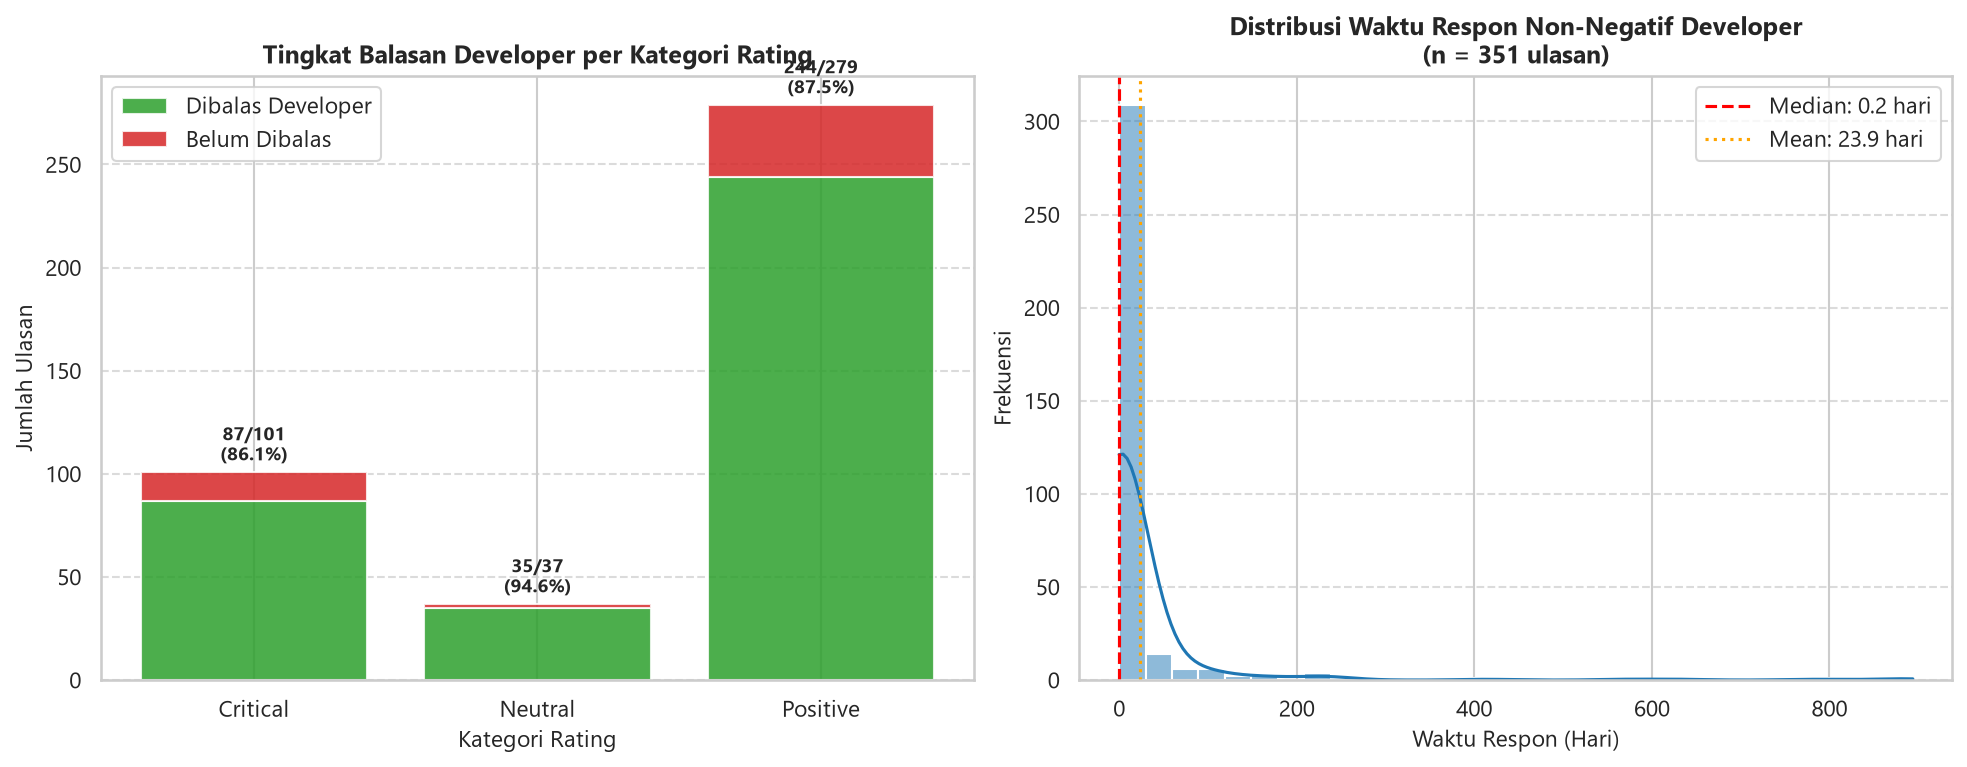

In [7]:
replied_df = processed_df[processed_df['has_developer_reply']].copy()
resp_times = replied_df['response_time_days'].dropna()

neg_mask = resp_times < 0
pos_mask = resp_times >= 0

print(f'Total Ulasan Dibalas: {len(resp_times)} ulasan')
print(f'- Selisih waktu respon non-negatif: {pos_mask.sum()} ulasan ({(pos_mask.sum()/len(resp_times)*100):.1f}%)')
print(f'- Selisih waktu respon negatif (anomali temporal): {neg_mask.sum()} ulasan ({(neg_mask.sum()/len(resp_times)*100):.1f}%)')

stat_all = resp_times.describe().to_frame('Seluruh Balasan (n=366)')
stat_pos = resp_times[pos_mask].describe().to_frame('Non-Negatif Saja (n=351)')
stat_neg = resp_times[neg_mask].describe().to_frame('Anomali Negatif (n=15)')

display(pd.concat([stat_all, stat_pos, stat_neg], axis=1).round(2))

# Visualisasi Waktu Respon & Tingkat Balasan
fig, axes = plt.subplots(1, 2, figsize=(13, 5), layout='constrained')

# Subplot 1: Status Balasan Developer per Kategori Rating
reply_cat = processed_df.groupby(['rating_category', 'has_developer_reply']).size().unstack(fill_value=0)
reply_cat = reply_cat.reindex(['critical', 'neutral', 'positive'])

bars_replied = axes[0].bar(reply_cat.index.str.capitalize(), reply_cat[True], label='Dibalas Developer', color='#2CA02C', alpha=0.85)
bars_unreplied = axes[0].bar(reply_cat.index.str.capitalize(), reply_cat[False], bottom=reply_cat[True], label='Belum Dibalas', color='#D62728', alpha=0.85)
axes[0].set_title('Tingkat Balasan Developer per Kategori Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kategori Rating', fontsize=11)
axes[0].set_ylabel('Jumlah Ulasan', fontsize=11)
axes[0].legend(loc='upper left')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

for i, cat in enumerate(reply_cat.index):
    total = reply_cat.loc[cat].sum()
    dibalas = reply_cat.loc[cat, True]
    rate = dibalas / total * 100
    axes[0].annotate(f'{dibalas}/{total}\n({rate:.1f}%)',
                     xy=(i, total), xytext=(0, 3), textcoords="offset points",
                     ha='center', va='bottom', fontsize=9, fontweight='bold')

# Subplot 2: Distribusi Waktu Respon Non-Negatif (Hari)
sns.histplot(resp_times[pos_mask], bins=30, ax=axes[1], color='#1F77B4', kde=True)
median_val = resp_times[pos_mask].median()
mean_val = resp_times[pos_mask].mean()
axes[1].axvline(median_val, color='red', linestyle='--', linewidth=1.5, label=f'Median: {median_val:.1f} hari')
axes[1].axvline(mean_val, color='orange', linestyle=':', linewidth=1.5, label=f'Mean: {mean_val:.1f} hari')
axes[1].set_title('Distribusi Waktu Respon Non-Negatif Developer\n(n = 351 ulasan)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Waktu Respon (Hari)', fontsize=11)
axes[1].set_ylabel('Frekuensi', fontsize=11)
axes[1].legend(loc='upper right')
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

fig_path_reply = FIG_DIR / 'playstore_rating_balasan.png'
plt.savefig(fig_path_reply, dpi=200)
print(f'Figur tersimpan: {fig_path_reply}')
plt.show()


## 7. Karakteristik Panjang Teks Ulasan

Pengguna yang merasa puas cenderung menulis ulasan singkat (misal: *"Bagus", "Sangat membantu"*), sedangkan pengguna yang menghadapi kendala cenderung memberikan ulasan panjang yang mendeskripsikan secara rinci error, langkah reproduksi, atau kekecewaan mereka.


,ulasan_count,mean_chars,median_chars,mean_words,median_words,max_words
rating_category,,,,,,
critical,101,95.2,63.0,15.7,10.0,79
neutral,37,128.9,63.0,20.5,10.0,88
positive,279,58.3,39.0,9.1,6.0,88


C:\Users\Yafi Rafsanjani H\AppData\Local\Temp\ipykernel_20420\2766150023.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=processed_df, x='rating_category', y='word_count',
C:\Users\Yafi Rafsanjani H\AppData\Local\Temp\ipykernel_20420\2766150023.py:21: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Critical (1-2★)', 'Neutral (3★)', 'Positive (4-5★)'])


D:\FILE KULIAH\semester 5\magang\zahir_social_analytics\.venv_social\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 9733 (\N{BLACK STAR}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


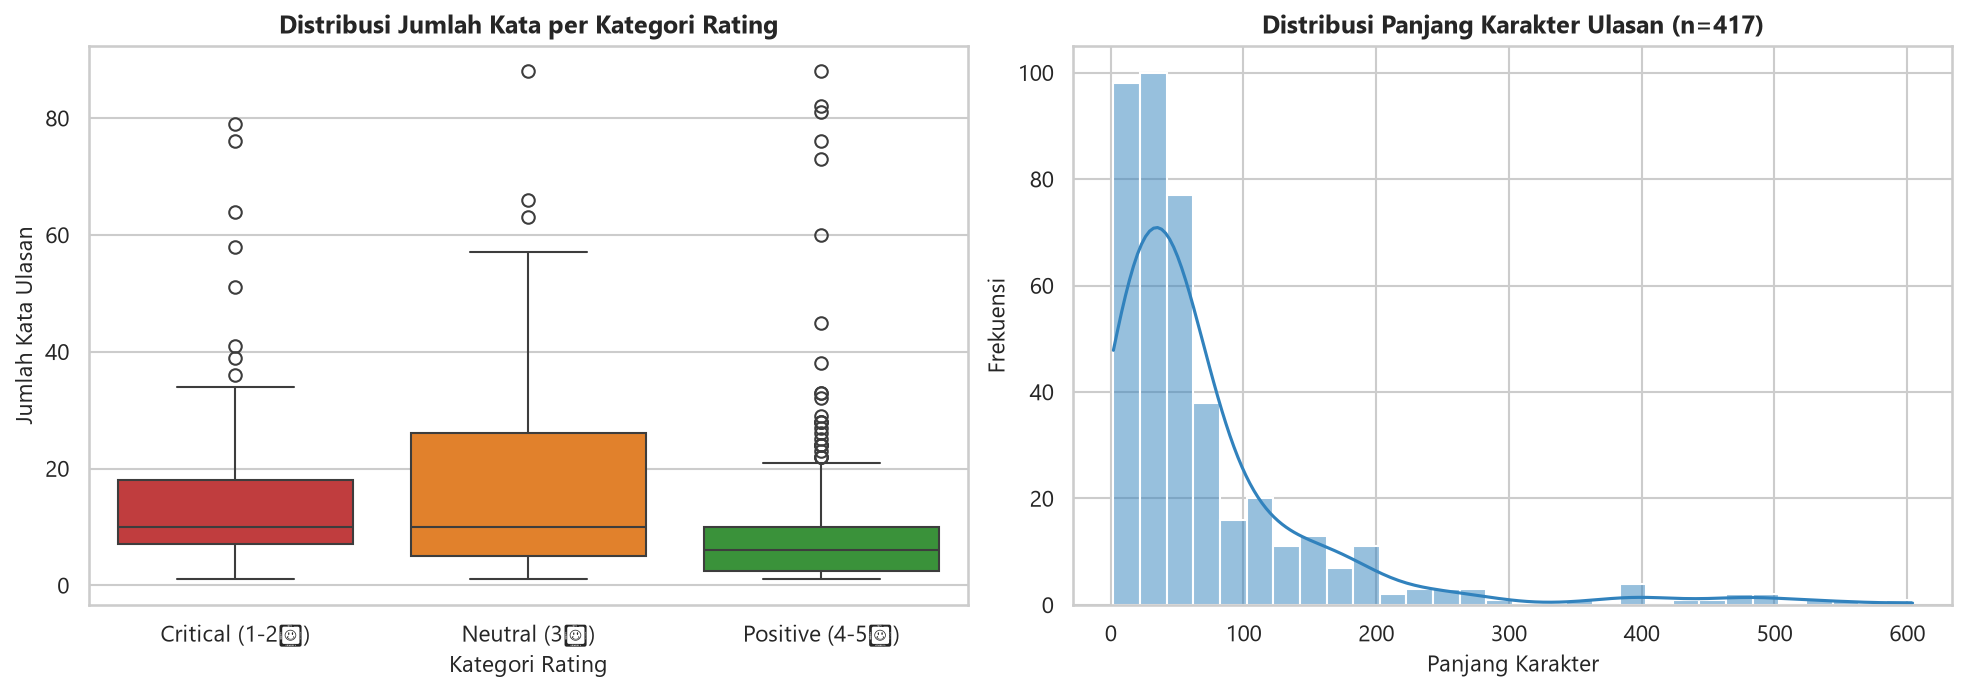

In [8]:
text_stats = processed_df.groupby('rating_category').agg(
    ulasan_count=('review_id', 'count'),
    mean_chars=('text_length_chars', 'mean'),
    median_chars=('text_length_chars', 'median'),
    mean_words=('word_count', 'mean'),
    median_words=('word_count', 'median'),
    max_words=('word_count', 'max')
).reindex(['critical', 'neutral', 'positive']).round(1)

display(text_stats)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), layout='constrained')

# Boxplot Jumlah Kata per Kategori Rating
sns.boxplot(data=processed_df, x='rating_category', y='word_count',
            order=['critical', 'neutral', 'positive'],
            palette=['#D62728', '#FF7F0E', '#2CA02C'], ax=axes[0])
axes[0].set_title('Distribusi Jumlah Kata per Kategori Rating', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Kategori Rating', fontsize=11)
axes[0].set_ylabel('Jumlah Kata Ulasan', fontsize=11)
axes[0].set_xticklabels(['Critical (1-2★)', 'Neutral (3★)', 'Positive (4-5★)'])

# Histogram Panjang Karakter Keseluruhan
sns.histplot(processed_df['text_length_chars'], bins=30, ax=axes[1], color='#3182BD', kde=True)
axes[1].set_title(f'Distribusi Panjang Karakter Ulasan (n={len(processed_df):,})', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Panjang Karakter', fontsize=11)
axes[1].set_ylabel('Frekuensi', fontsize=11)

plt.show()


## 8. Observasi Sinyal Kualitatif Suara Pelanggan (Customer Voice)

Sampel ulasan kritis menyoroti area friksi utama:
- Masalah otentikasi login / forgot password.
- Kendala sinkronisasi data cloud / offline-online.
- Force close / crash saat mencetak struk atau membuka transaksi.


In [9]:
critical_samples = processed_df[processed_df['score'] == 1][['app_name', 'score', 'review_text_clean']].head(4)
print('=== CONTOH SINYAL KRITIS (RATING 1 BINTANG) ===')
for idx, row in critical_samples.iterrows():
    print(f"[{row['app_name']}] (Rating {row['score']}): \"{row['review_text_clean'][:120]}...\"")

positive_samples = processed_df[processed_df['score'] == 5][['app_name', 'score', 'review_text_clean']].head(3)
print('\n=== CONTOH SINYAL POSITIF (RATING 5 BINTANG) ===')
for idx, row in positive_samples.iterrows():
    print(f"[{row['app_name']}] (Rating {row['score']}): \"{row['review_text_clean'][:120]}...\"")


=== CONTOH SINYAL KRITIS (RATING 1 BINTANG) ===
[Zahir Attendance] (Rating 1): "buruk..."
[Zahir Attendance] (Rating 1): "aplikasi macam apa ini, ga bisa absen. wajah tidak terdeteksi..."
[Zahir Attendance] (Rating 1): "Apk Sampah selalu error tiap kali di gunakan Harus logout dulu trus login baru bisa di gunakan 👎..."
[Zahir Attendance] (Rating 1): "Ada cara daftar selain pakai email? SMS atau wa? Krn sdh pakai email tetap saja tertulis..email atau password salah.. ad..."

=== CONTOH SINYAL POSITIF (RATING 5 BINTANG) ===
[Zahir Attendance] (Rating 5): "aplikasi tidak kompatibel terus dihp saya,kenapa ya?..."
[Zahir Attendance] (Rating 5): "Bagus dan mudah..."
[Zahir Attendance] (Rating 5): "Ok..."


## 9. Output Staging Opsional

Default bersifat read-only. Jika `WRITE_STAGING = True`, hasil transformasi disimpan ke direktori laporan staging untuk audit kesetaraan, tanpa menimpa dataset kanonikal `data/final/`.


In [10]:
WRITE_STAGING = False

if WRITE_STAGING:
    staging_path = ROOT / 'outputs' / 'reports' / 'playstore_preprocessing_staging.csv'
    staging_path.parent.mkdir(parents=True, exist_ok=True)
    processed_df.to_csv(staging_path, index=False, encoding='utf-8-sig')
    print(f'Dataset hasil staging berhasil ditulis ke: {staging_path}')
    print(f'Ukuran staging: {processed_df.shape[0]} baris, {processed_df.shape[1]} kolom.')
else:
    print('Mode Staging tidak aktif (WRITE_STAGING = False). Dataset kanonikal tetap aman dan tidak tersentuh.')


Mode Staging tidak aktif (WRITE_STAGING = False). Dataset kanonikal tetap aman dan tidak tersentuh.


## 10. Kesimpulan & Ringkasan Temuan EDA

1. **Kelengkapan Dataset**: Seluruh 417 ulasan mentah terproses sempurna ke dalam 21 kolom analitik terstandarisasi tanpa kehilangan satu pun observasi (0 baris hilang, 0 baris terduplikasi).
2. **Pola Kepuasan Pelanggan**:
   - Mayoritas pengguna puas (66.91% rating bintang 4-5), dengan Zahir Attendance (4.25★) dan Zahir Simple Start (4.19★) memperoleh skor tertinggi.
   - Zahir Online (3.33★) dan Zahir Certification (3.05★) memiliki proporsi kritik tertinggi (~37% dan ~50%), menuntut perhatian teknis pada stabilitas sinkronisasi dan akses ujian.
3. **Responsivitas Pengembang**:
   - 87.77% ulasan dibalas, dengan responsivitas ulasan kritis mencapai 86.14%.
   - Selisih waktu respon negatif pada 15 ulasan disebabkan oleh pembaruan ulasan oleh pengguna setelah pengembang merespon, bukan kegagalan sistem.
4. **Karakteristik Teks**:
   - Ulasan kritis memiliki jumlah kata rata-rata yang lebih tinggi secara signifikan dibandingkan ulasan positif, menyediakan data tekstual kaya untuk analisis aspek dan topik pada notebook berikutnya (`05_aspect_analysis.ipynb`).
